# Week 3: OLS Demand Model

In [11]:
import numpy as np
import pandas as pd
pd.options.mode.chained_assignment = None 
import pickle

import os
from importlib import reload

import matplotlib.pyplot as plt
import matplotlib 
# import seaborn as sns
%matplotlib inline
plt.style.use('ggplot')
from matplotlib.ticker import MultipleLocator

### load competition data and show some stats

In [16]:
results_dir = os.path.join("..", "..", "results")

# Récupération de tous les fichiers CSV dans le dossier results
file_paths = [
    os.path.join(results_dir, f)
    for f in os.listdir(results_dir)
    if f.startswith("duopoly_competition_details") and f.endswith(".csv")
]

# Fusion et suppression des doublons
df_comp_details = pd.concat(
    [pd.read_csv(f) for f in file_paths], ignore_index=True
)
df_comp_details.drop_duplicates(inplace=True)

# Traitement des valeurs manquantes et calcul du revenu
df_comp_details.fillna(0, inplace=True)
df_comp_details["revenue"] = (
    df_comp_details["price"] * df_comp_details["demand"]
)

df_comp_details.head(3)

# 1. Nombre de fichiers détectés
print(f"Nombre de fichiers trouvés : {len(file_paths)}\n")

# 2. Somme des lignes individuelles
total_lignes = sum(len(pd.read_csv(f)) for f in file_paths)

print(f"Somme des lignes des 4 fichiers : {total_lignes}")
print(
    f"Lignes dans df_comp_details (avant nettoyage) : {len(df_comp_details)}"
)

Nombre de fichiers trouvés : 4

Somme des lignes des 4 fichiers : 200000
Lignes dans df_comp_details (avant nettoyage) : 200000


In [17]:
df_comp_details['unique_selling_season_key'] = df_comp_details.apply(lambda r:
                                "%s_%s" % (r.competition_id,r.selling_season), axis=1)

In [18]:
dfx_rev = df_comp_details.groupby('unique_selling_season_key').agg({
    'revenue' : 'sum'
}).reset_index()
dfx_rev.head(3)

,unique_selling_season_key,revenue
0,339UBs_1,0.0
1,339UBs_10,30.0
2,339UBs_100,90.0


# Let us build our own demand model based on the competition data.

## => f(price, competitor_price) = demand

## idea:
- split selling_season into sub-intervals where we assume a constant demand model
    - e.g. selling period [1,20] assumed to have almost constant demand
- estimate the demand model per competition
- train on first 50 selling_seasons and evaluate on the last 50

45GaaD


<Axes: >

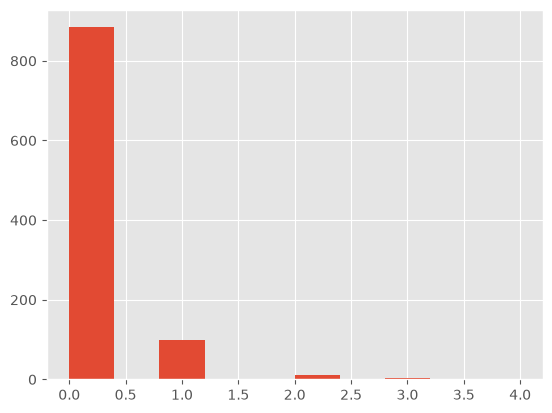

In [22]:
comp = df_comp_details.competition_id.unique()[1]
print(comp)

# filter on first competion_id
df = df_comp_details[df_comp_details.competition_id==comp ]

# concentrate on selling period in [1,20]
df = df[df.selling_period <= 20 ]

df_train = df[df.selling_season<=50]
df_test = df[df.selling_season>50]

df_train.demand.hist()

<Axes: >

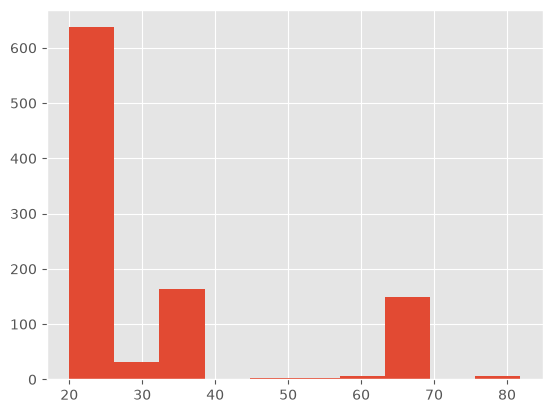

In [23]:
# df_train.head(35)
# df_train.demand.hist()
df_train.price.hist()

<Axes: >

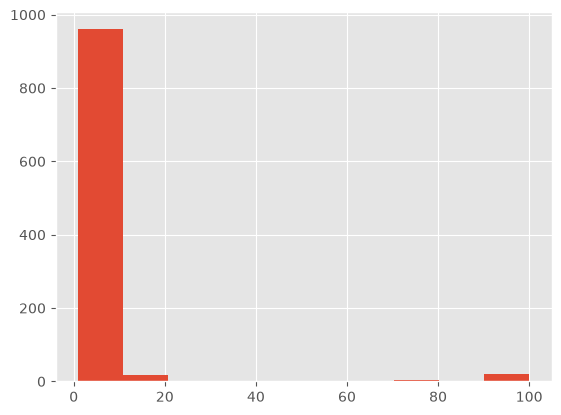

In [24]:
df_train.price_competitor.hist()

## (a) fit OLS model

In [25]:
import statsmodels.api as sm
# https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.OLS.html

y = df_train.demand
X = df_train[['price', 'price_competitor']] 
X['intercept'] = 1


mod = sm.OLS(y, X)
# mod = sm.regression.quantile_regression.QuantReg(y,X)

res = mod.fit()

print(res.summary())

                            OLS Regression Results                            
Dep. Variable:                 demand   R-squared:                       0.133
Model:                            OLS   Adj. R-squared:                  0.131
Method:                 Least Squares   F-statistic:                     76.51
Date:                Fri, 30 Oct 2026   Prob (F-statistic):           1.23e-31
Time:                        16:34:32   Log-Likelihood:                -489.26
No. Observations:                1000   AIC:                             984.5
Df Residuals:                     997   BIC:                             999.2
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
price               -0.0045      0.001  

## (b) predict demand based on function for
- own price = 30
- competitor price = 50

In [26]:
mod.predict(res.params, [30,50,1])

np.float64(0.5459051746772237)

## (c) simulate demand, our prices in [1,100] and competitor_price = 50

In [27]:

def est_demand(price, comp_price, para = res.params):
    demand = mod.predict(para, [price, comp_price, 1])
    demand = max(0,demand)
    return demand


df_sim = pd.DataFrame(columns = ['comp_price','price','demand','rev'])
for comp_price in np.arange(1,101,1):
    for p in np.arange(1,101,1):
        demand = est_demand(price=p, comp_price=comp_price)
        rev = p * demand
        df_sim.loc[len(df_sim)] = [comp_price,p,demand,rev]

    
df_sim.head()

# Generate a new data frame containing the comp_price, your corresponding optimal price, and the corresponding revenue
# We group by 'comp_price' and 'rev' and compute nehmen den maximalen 'price2'
idx_max_rev = df_sim.groupby('comp_price')['rev'].idxmax()

df_result = df_sim.loc[idx_max_rev, ['comp_price', 'price', 'rev']]
print(df_result)

df_opt_price = df_result[['comp_price', 'price']].reset_index(drop=True)
print(df_opt_price)




      comp_price  price        rev
21           1.0   22.0   2.145418
122          2.0   23.0   2.366820
223          3.0   24.0   2.598994
324          4.0   25.0   2.841940
425          5.0   26.0   3.095659
...          ...    ...        ...
9599        96.0  100.0  68.569203
9699        97.0  100.0  69.557732
9799        98.0  100.0  70.546260
9899        99.0  100.0  71.534788
9999       100.0  100.0  72.523317

[100 rows x 3 columns]
    comp_price  price
0          1.0   22.0
1          2.0   23.0
2          3.0   24.0
3          4.0   25.0
4          5.0   26.0
..         ...    ...
95        96.0  100.0
96        97.0  100.0
97        98.0  100.0
98        99.0  100.0
99       100.0  100.0

[100 rows x 2 columns]


#### plot demand and revenue curve

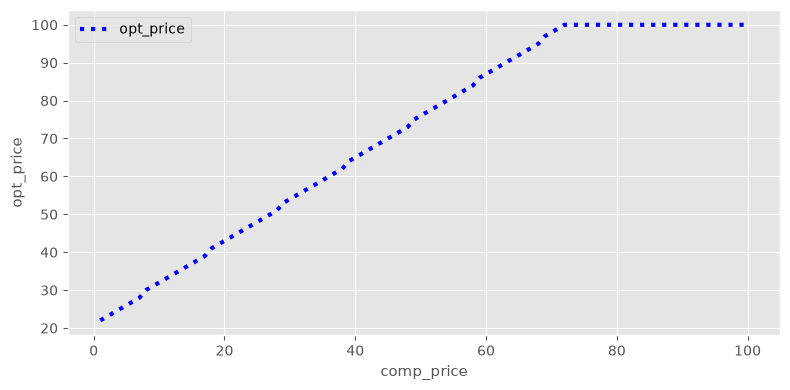

In [29]:
fig, ax = plt.subplots(figsize=(8, 4))

# Ensure data is sorted by competitor price so the line renders smoothly
df_plot = df_opt_price.sort_values("comp_price")

ax.plot(
    df_plot["comp_price"],
    df_plot["price"],
    color="b",
    linestyle="dotted",
    linewidth=3,
    label="opt_price",
)

ax.tick_params(axis="both", labelsize=10)

# Legend for single axis
ax.legend(loc="best")

ax.set_xlabel("comp_price", size=11)
ax.set_ylabel("opt_price", size=11)

ax.grid(True)
fig.tight_layout()

plt.show()

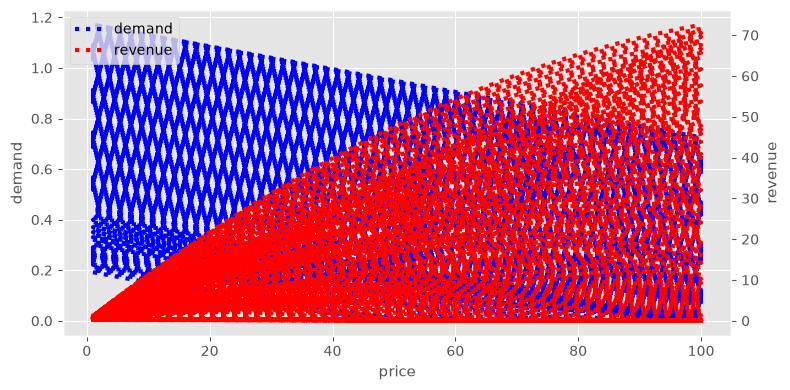

In [30]:
fig, ax = plt.subplots(figsize=(8,4))

ax.plot(df_sim['price'], df_sim['demand'], color='b', 
        linestyle='dotted', linewidth=3, label='demand')

ax_2 = ax.twinx()
ax_2.grid(False)
ax_2.plot(df_sim['price'], df_sim['rev'], color='r', 
        linestyle='dotted', linewidth=3, label='revenue')

ax_2.tick_params(axis="both", labelsize=10)
ax.tick_params(axis="both", labelsize=10)

# legend
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax_2.get_legend_handles_labels()
ax_2.legend(lines + lines2, labels + labels2, loc=0)

ax.set_xlabel('price', size=11)
ax.set_ylabel("demand" , size=11)
ax_2.set_ylabel("revenue" , size=11)

ax.grid(True)
fig.tight_layout()

plt.show()

## (d) compute estimated demand in computation details

In [31]:
df_eval = df_test[['unique_selling_season_key','selling_season','selling_period','price_competitor', 'price', 'demand']]

df_eval.head(5)

,unique_selling_season_key,selling_season,selling_period,price_competitor,price,demand
15000,45GaaD_51,51,1,1.0,65.0,0
15001,45GaaD_51,51,2,3.0,65.0,0
15002,45GaaD_51,51,3,7.0,65.0,0
15003,45GaaD_51,51,4,7.0,32.5,0
15004,45GaaD_51,51,5,7.0,32.5,0


In [32]:
# estimate demand
# estimate demand
df_eval['est_demand'] = df_eval.apply(lambda r:
            est_demand(price=r.price, comp_price=r.price_competitor),
            axis=1)

# compute error metrics
df_eval['est_error'] = df_eval['est_demand'] - df_eval['demand']
df_eval['abs_est_error'] = df_eval['est_error'].abs()


df_eval.head(5)

,unique_selling_season_key,selling_season,selling_period,price_competitor,price,demand,est_demand,est_error,abs_est_error
15000,45GaaD_51,51,1,1.0,65.0,0,0.00000,0.00000,0.00000
15001,45GaaD_51,51,2,3.0,65.0,0,0.00000,0.00000,0.00000
15002,45GaaD_51,51,3,7.0,65.0,0,0.00000,0.00000,0.00000
15003,45GaaD_51,51,4,7.0,32.5,0,0.10959,0.10959,0.10959
15004,45GaaD_51,51,5,7.0,32.5,0,0.10959,0.10959,0.10959


In [33]:
df_eval[['demand', 'est_demand', 'est_error', 'abs_est_error']].describe()

,demand,est_demand,est_error,abs_est_error
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,0.126000,0.141895,0.015895,0.211570
std,0.379827,0.130155,0.342821,0.270135
min,0.000000,0.000000,-1.973778,0.000000
25%,0.000000,0.109590,0.000000,0.109590
50%,0.000000,0.165829,0.147370,0.165829
75%,0.000000,0.175714,0.175714,0.175714
max,3.000000,1.085160,1.085160,1.973778


### plot the actual demand vs. estimated demand for one test selling season

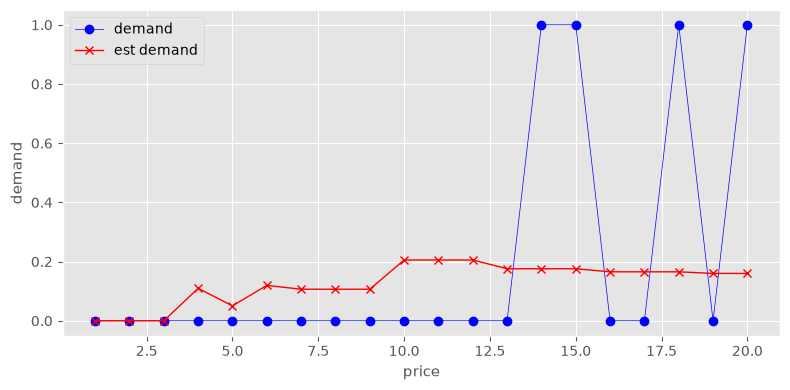

In [35]:
dfe = df_eval[df_eval.selling_season==60]

fig, ax = plt.subplots(figsize=(8,4))

ax.plot(dfe['selling_period'], dfe['demand'], color='b', 
        linestyle='-', marker='o', linewidth=0.5, markersize=6, label='demand')

ax.plot(dfe['selling_period'], dfe['est_demand'], color='r', 
        linestyle='-', marker='x', linewidth=1, markersize=6, label='est demand')

ax.legend( loc=0)

ax.set_xlabel('price', size=11)
ax.set_ylabel("demand" , size=11)

ax.grid(True)
fig.tight_layout()

plt.show()

# next tasks:
## (1) estimate five demand models covering the 100 period selling_season
## (2) estimate demand models for every simulation_id 
## (3) implement the demand model in your own simulation (last week simulation notebook)
## (4) implement the demand model estimation & next price optimization in your pricing algorithm